# APRAU 2026/27 — Trabalho 1
## Parte 1: Análise Exploratória de Dados (EDA)

**Dataset:** `dataset_grupo_22.csv` (2000 pacientes, 33 features + 2 targets)

Objetivos desta secção:
1. **Estatística descritiva**: qualidade dos dados, tipos, medidas de tendência central e dispersão.
2. **Análise univariada**: distribuição de cada feature e das duas variáveis alvo.
3. **Análise bivariada**: correlação entre features e relação de cada feature com `target_regression` (regressão) e `target_class` (classificação).
4. **Identificar features pouco informativas, constantes ou redundantes**, com justificação.

In [32]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

dataset_name = 'dataset_grupo_22.csv'
dataset_candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f'Não foi encontrado {dataset_name}. Execute o notebook a partir da raiz do projeto '
        'ou da pasta notebooks.'
    )

df = pd.read_csv(dataset_path)
print(df.shape)
df.head()

(2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Normal,Never,87,0.977,23.600,7.080,176.000,6.500,165.000,High,No,Medium,No,No,146.239,Low,7.897,12.253,113.000,104.000,24.600,14.300,89.000,72.000,92.000,Tertiary,Retired,113.000,9.420,1.415,166.000,90.000,DI_HY
1,Mature,Female,Obese,Never,56,0.621,36.700,8.200,225.756,6.859,254.443,High,No,High,Yes,Yes,149.058,Low,7.313,11.922,133.613,89.786,14.889,8.461,74.660,64.331,127.944,Tertiary,Unemployed,133.613,9.420,0.953,188.000,220.000,DI_HY
2,Mature,Male,Obese,Current,67,0.747,39.800,6.862,290.000,6.300,144.000,High,Yes,Low,No,Yes,148.563,Low,7.561,12.723,119.000,106.000,17.100,7.700,54.000,81.000,161.000,Tertiary,Employed,119.000,9.420,1.077,71.000,172.000,DI_HY
3,Middle,Female,Normal,Current,39,0.425,21.400,6.900,159.000,9.800,193.000,Low,No,Low,Yes,No,150.420,Medium,7.440,12.269,123.000,106.000,2.700,6.400,96.000,35.000,120.000,Secondary,Employed,123.000,9.420,1.579,185.000,92.000,DI_HY
4,Senior,Female,Normal,Never,74,0.828,23.000,7.080,163.000,6.500,88.000,High,No,Low,No,Yes,146.239,Low,7.897,12.253,133.000,96.000,6.400,7.000,99.000,45.000,172.000,Secondary,Retired,133.000,9.420,0.965,131.338,152.000,DI_HY


## 1. Estatística descritiva
### 1.1 Estrutura e qualidade dos dados

In [33]:
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

num_cols = [c for c in df.select_dtypes(include='number').columns if c != TARGET_REG]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

print(f'Features numéricas ({len(num_cols)}): {num_cols}\n')
print(f'Features categóricas ({len(cat_cols)}): {cat_cols}\n')
print('Valores em falta (total):', df.isna().sum().sum())
print('Linhas duplicadas:', df.duplicated().sum())

pd.DataFrame({'dtype': df.dtypes.astype(str),
              'n_unique': df.nunique(),
              'missing': df.isna().sum()})

Features numéricas (21): ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']

Features categóricas (12): ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']

Valores em falta (total): 0
Linhas duplicadas: 0


,dtype,n_unique,missing
age_level,str,4,0
gender,str,2,0
bmi_level,str,4,0
smoking,str,3,0
age,int64,72,0
age_normalized,float64,131,0
bmi,float64,487,0
HbA1c_level,float64,110,0
cholesterol,float64,211,0
sleep_hours,float64,217,0


Não há valores em falta nem linhas duplicadas, pelo que não é preciso imputar nem remover registos.
As features categóricas estão como texto e vão ter de ser codificadas (ordinal ou one-hot) antes da modelação.

### 1.2 Features numéricas

In [34]:
desc = df[num_cols + [TARGET_REG]].describe().T
desc['cv'] = desc['std'] / desc['mean']            # coeficiente de variação
desc['skew'] = df[num_cols + [TARGET_REG]].skew()
desc['kurtosis'] = df[num_cols + [TARGET_REG]].kurt()
desc['n_unique'] = df[num_cols + [TARGET_REG]].nunique()
desc

,count,mean,std,min,25%,50%,75%,max,cv,skew,kurtosis,n_unique
age,2000.000,55.191,20.286,18.000,38.000,57.000,73.000,89.000,0.368,-0.160,-1.146,72
age_normalized,2000.000,0.611,0.233,0.184,0.414,0.632,0.816,1.000,0.381,-0.160,-1.146,131
bmi,2000.000,27.807,7.180,15.000,21.800,27.535,33.700,59.450,0.258,0.107,-0.701,487
HbA1c_level,2000.000,6.846,0.573,3.500,6.817,6.943,7.011,9.000,0.084,-1.416,9.654,110
cholesterol,2000.000,225.051,41.294,150.000,191.000,225.373,258.000,299.000,0.183,-0.011,-1.017,211
sleep_hours,2000.000,7.047,1.631,4.000,5.700,7.012,8.400,10.000,0.231,-0.014,-1.011,217
triglycerides,2000.000,158.239,65.382,50.000,104.000,151.000,209.000,399.000,0.413,0.436,0.021,310
blood_pressure,2000.000,150.145,5.221,120.000,149.058,149.974,151.266,180.000,0.035,-0.584,14.173,140
crp_level,2000.000,7.375,1.100,0.011,7.277,7.458,7.706,14.615,0.149,-0.306,14.981,191
homocysteine_level,2000.000,12.379,1.123,5.110,12.253,12.417,12.621,19.874,0.091,-0.683,19.018,191


**Observações principais:**
- `calcium_baseline` tem **desvio padrão 0** e um único valor (9.42): é uma **feature constante**, sem qualquer informação.
- `systolic_bp` e `systolic_index` têm estatísticas exatamente iguais, tal como `ldl` e `ldl_alternative`, e também `age` com `age_normalized` (que é uma reescala). Vamos confirmar na análise bivariada se são **redundantes**.
- `HbA1c_level`, `blood_pressure`, `crp_level` e `homocysteine_level` têm um IQR muito estreito face ao intervalo total (por exemplo `blood_pressure`: IQR ≈ 149–151, intervalo 120–180). Isto indica distribuições muito concentradas, com caudas longas e curtose alta.
- As escalas variam muito (de ~1 em `plasma_value` a ~400 em `triglycerides`), por isso será necessário **normalizar** para métodos sensíveis à escala (regularização Ridge/Lasso, por exemplo).

### 1.3 Features categóricas

In [35]:
cat_summary = pd.DataFrame({
    'n_categorias': df[cat_cols + [TARGET_CLS]].nunique(),
    'moda': df[cat_cols + [TARGET_CLS]].mode().iloc[0],
    'freq_moda_%': [df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols + [TARGET_CLS]],
})
cat_summary

,n_categorias,moda,freq_moda_%
age_level,4,Senior,33.000
gender,2,Male,51.350
bmi_level,4,Obese,40.200
smoking,3,Never,35.650
physical_activity,3,Moderate,34.150
family_history,2,No,51.700
stress_level,3,High,35.350
low_hdl_cholesterol,2,No,82.350
high_ldl_cholesterol,2,Yes,51.100
sugar_consumption,3,Low,36.850


In [36]:
for c in cat_cols + [TARGET_CLS]:
    print(f'{c}: ', df[c].value_counts().to_dict())

age_level:  {'Senior': 660, 'Mature': 653, 'Middle': 542, 'Young': 145}
gender:  {'Male': 1027, 'Female': 973}
bmi_level:  {'Obese': 804, 'Normal': 498, 'Overweight': 454, 'Underweight': 244}
smoking:  {'Never': 713, 'Former': 660, 'Current': 627}
physical_activity:  {'Moderate': 683, 'High': 668, 'Low': 649}
family_history:  {'No': 1034, 'Yes': 966}
stress_level:  {'High': 707, 'Low': 652, 'Medium': 641}
low_hdl_cholesterol:  {'No': 1647, 'Yes': 353}
high_ldl_cholesterol:  {'Yes': 1022, 'No': 978}
sugar_consumption:  {'Low': 737, 'Medium': 654, 'High': 609}
education_level:  {'Tertiary': 676, 'Secondary': 670, 'Primary': 654}
employment_status:  {'Employed': 679, 'Retired': 666, 'Unemployed': 655}
target_class:  {'DI_HY': 1798, 'HT': 117, 'DI_HT': 85}


## 2. Análise univariada
### 2.1 Variáveis alvo

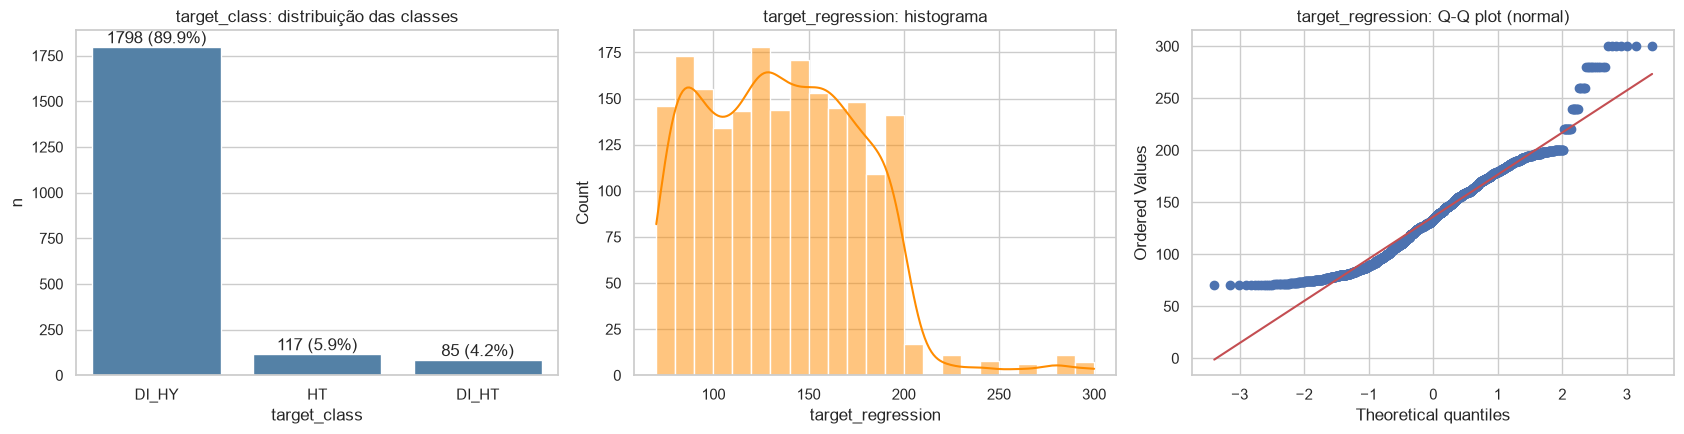

Rácio de desequilíbrio (maioritária / minoritária): 21.2
target_regression -> skew = 0.52, kurtosis = 0.42


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df[TARGET_CLS].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], color='steelblue')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f'{v} ({v/len(df):.1%})', ha='center')
axes[0].set_title('target_class: distribuição das classes'); axes[0].set_ylabel('n')

sns.histplot(df[TARGET_REG], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('target_regression: histograma')

stats.probplot(df[TARGET_REG], dist='norm', plot=axes[2])
axes[2].set_title('target_regression: Q-Q plot (normal)')
plt.tight_layout(); plt.show()

print(f"Rácio de desequilíbrio (maioritária / minoritária): {counts.max() / counts.min():.1f}")
print(f"target_regression -> skew = {df[TARGET_REG].skew():.2f}, kurtosis = {df[TARGET_REG].kurt():.2f}")

- **`target_class` está muito desequilibrada**: `DI_HY` representa cerca de 90% dos registos, contra cerca de 6% de `HT` e 4% de `DI_HT`.
  Um classificador que preveja sempre `DI_HY` já teria cerca de 90% de *accuracy*. Por isso, na classificação devemos usar métricas como **F1 macro, *balanced accuracy*, recall por classe e matriz de confusão**, com **estratificação** nos métodos de reamostragem e, eventualmente, `class_weight='balanced'`.
- **`target_regression`** varia entre 70 e 300 e tem uma ligeira assimetria positiva (cauda à direita).

### 2.2 Features numéricas: histogramas e boxplots

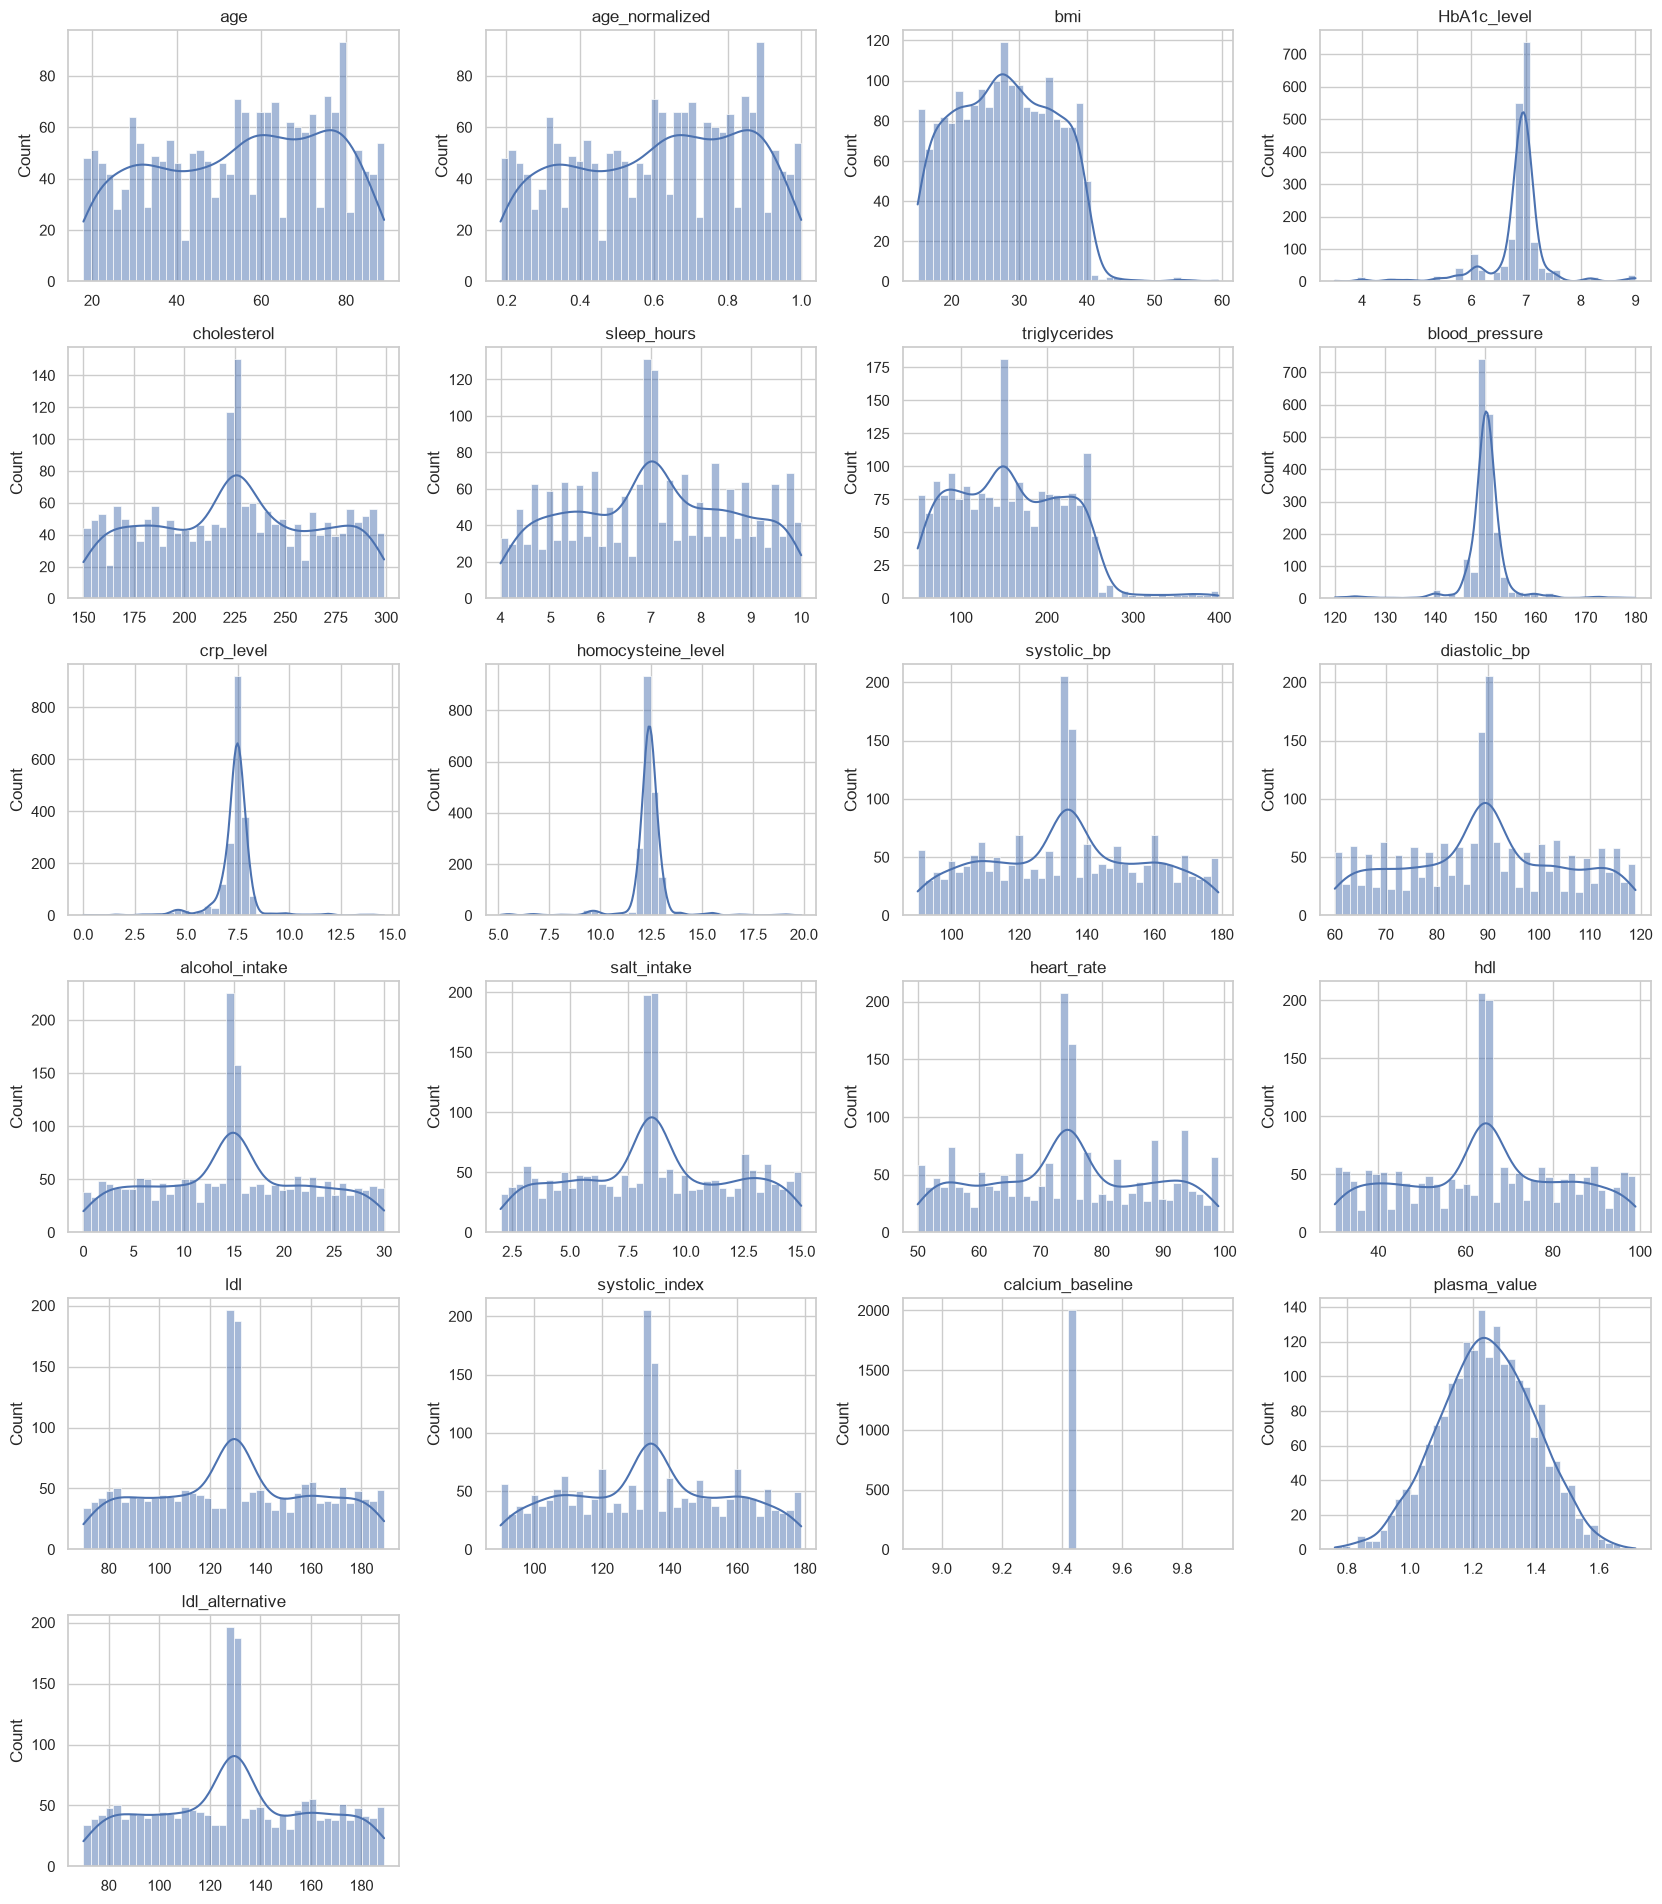

In [38]:
def grid_plot(cols, kind, ncols=4, size=(4.2, 3.2)):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0]*ncols, size[1]*nrows))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        if kind == 'hist':
            sns.histplot(df[c], kde=True, ax=ax, bins=40)
        else:
            sns.boxplot(x=df[c], ax=ax, color='lightsteelblue')
        ax.set_title(c); ax.set_xlabel('')
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

grid_plot(num_cols, 'hist')

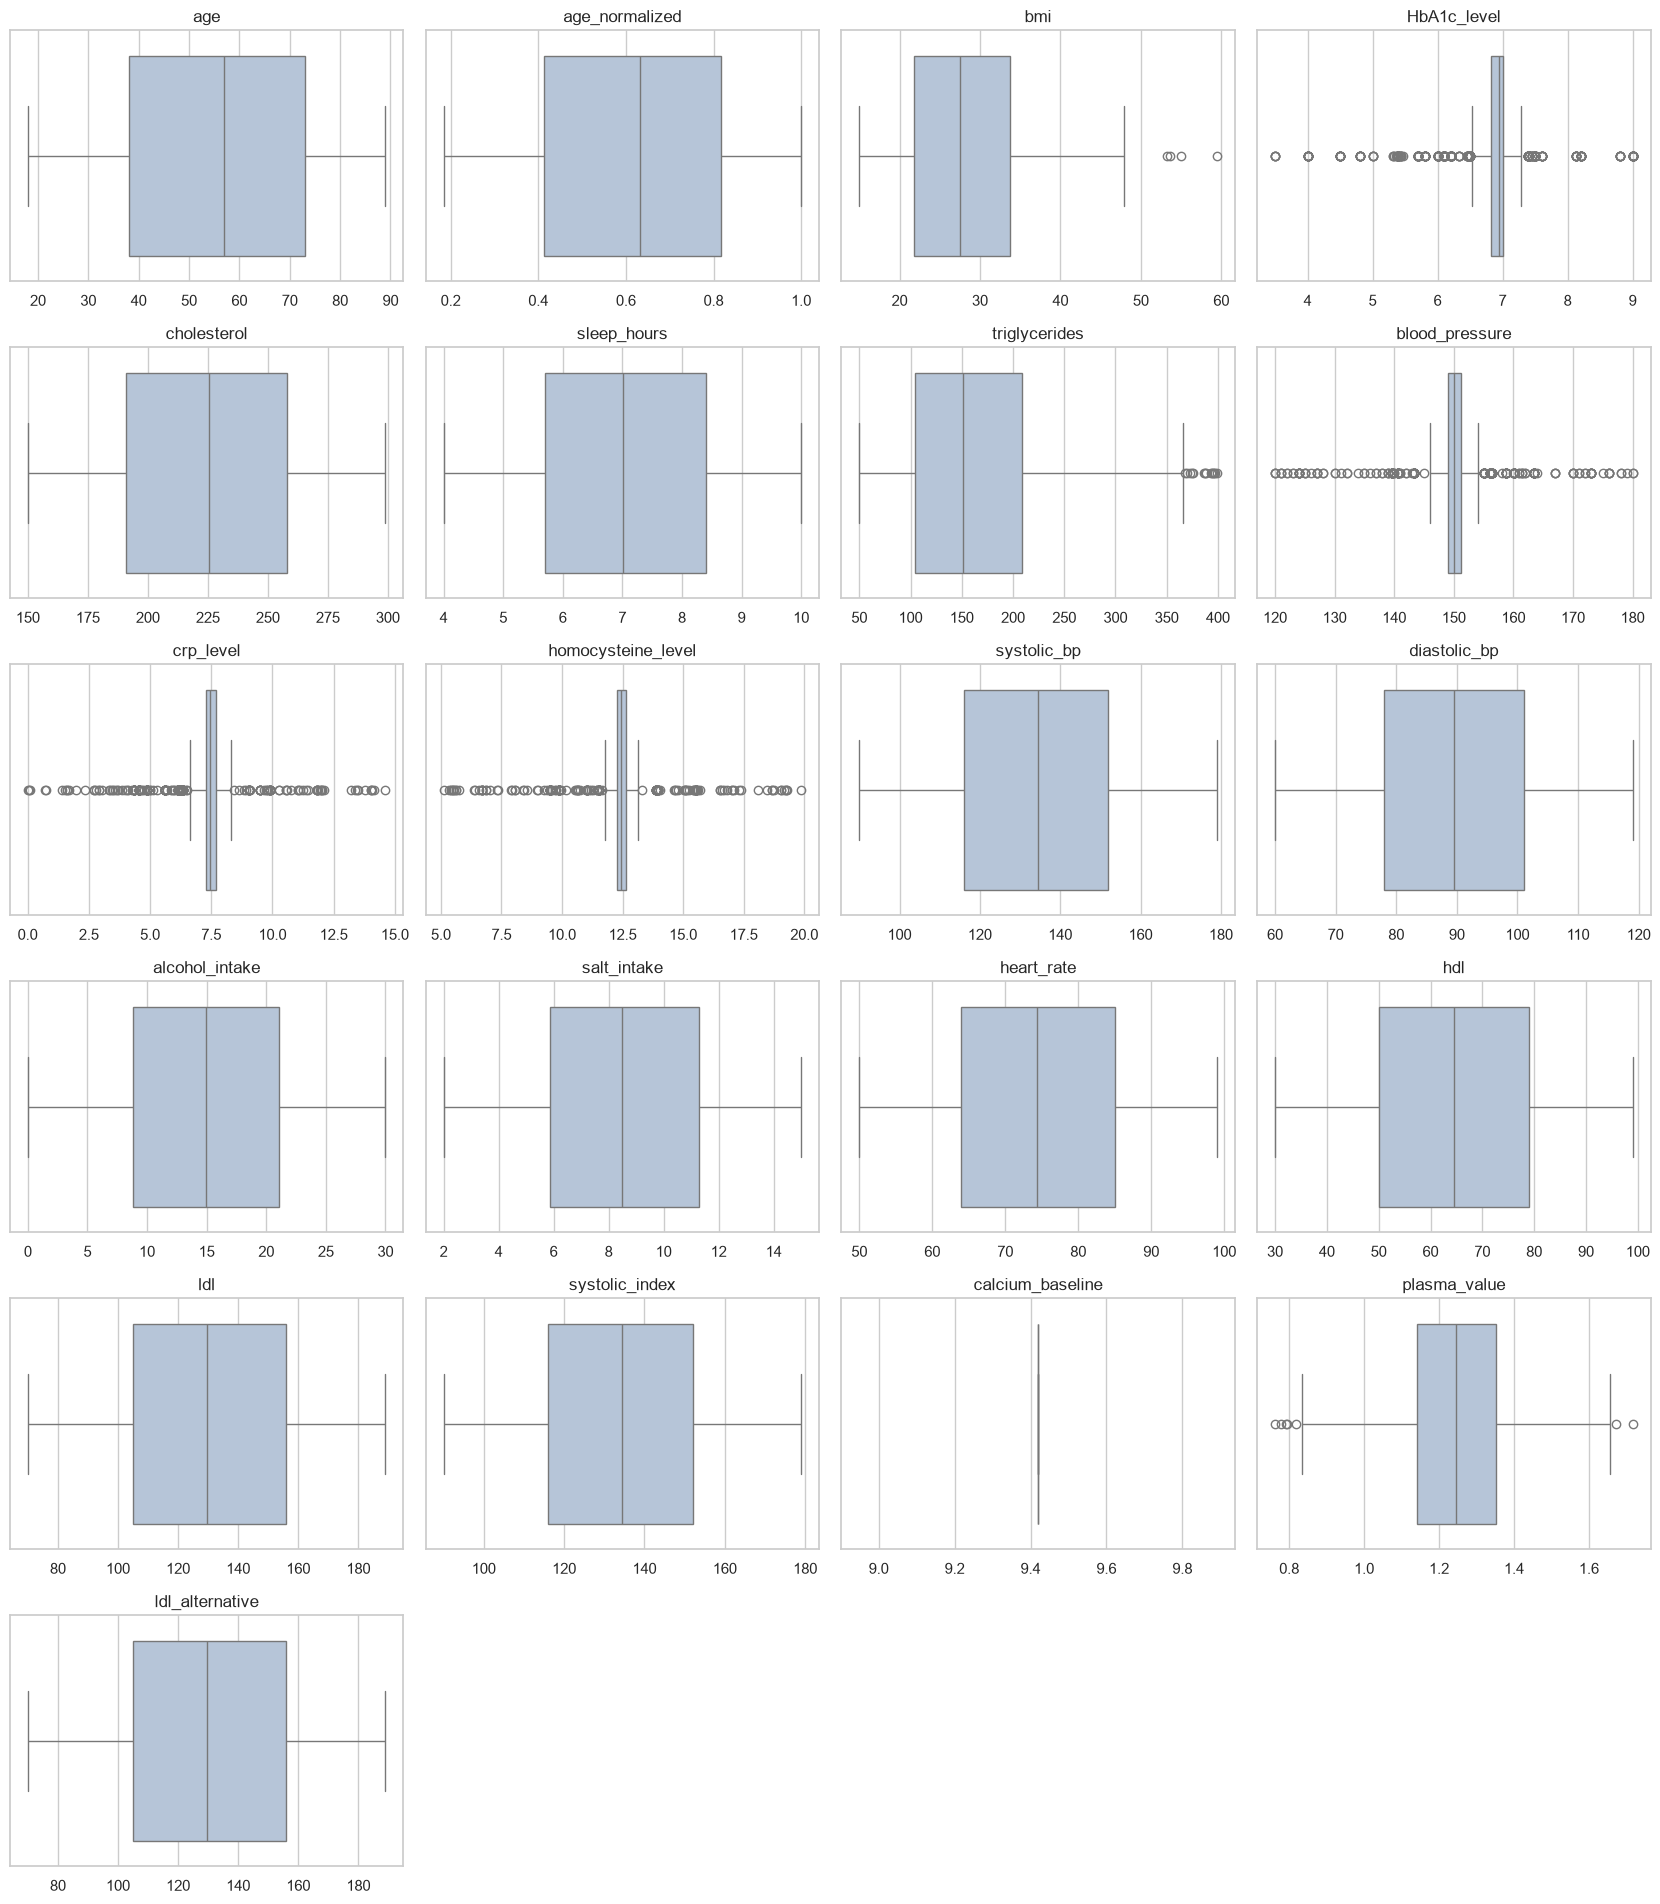

In [39]:
grid_plot(num_cols, 'box')

**Padrões de distribuição:**
- **Aproximadamente uniformes**: `age`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`. São distribuições "planas" e pouco realistas do ponto de vista clínico, o que sugere dados sintéticos.
- **Muito concentradas (leptocúrticas) com muitos *outliers***: `HbA1c_level`, `blood_pressure`, `crp_level`, `homocysteine_level`. A maior parte dos valores está num intervalo estreito e alguns pontos ficam muito afastados.
- **Assimetria positiva**: `bmi`, `triglycerides`.
- **`plasma_value`**: aproximadamente normal.
- **`calcium_baseline`**: um único valor (constante).

### 2.3 Deteção de outliers (regra do IQR)

In [40]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out = pd.DataFrame({'n_outliers': {c: iqr_outliers(df[c]) for c in num_cols + [TARGET_REG]}})
out['%'] = out['n_outliers'] / len(df) * 100
out.sort_values('n_outliers', ascending=False)

,n_outliers,%
HbA1c_level,372,18.600
crp_level,228,11.400
blood_pressure,212,10.600
homocysteine_level,170,8.500
target_regression,18,0.900
triglycerides,14,0.700
plasma_value,7,0.350
bmi,4,0.200
heart_rate,0,0.000
ldl_alternative,0,0.000


Os *outliers* concentram-se nas features leptocúrticas. Como o IQR destas variáveis é muito estreito, a regra 1.5×IQR marca como *outlier* muitos valores que são clinicamente plausíveis (por exemplo HbA1c de 5.4%).
Por isso **não os removemos automaticamente**. Na secção 3 vemos que, no caso de `HbA1c_level`, estes valores "extremos" estão associados a uma classe concreta (`HT`) e são informativos.

### 2.4 Features categóricas

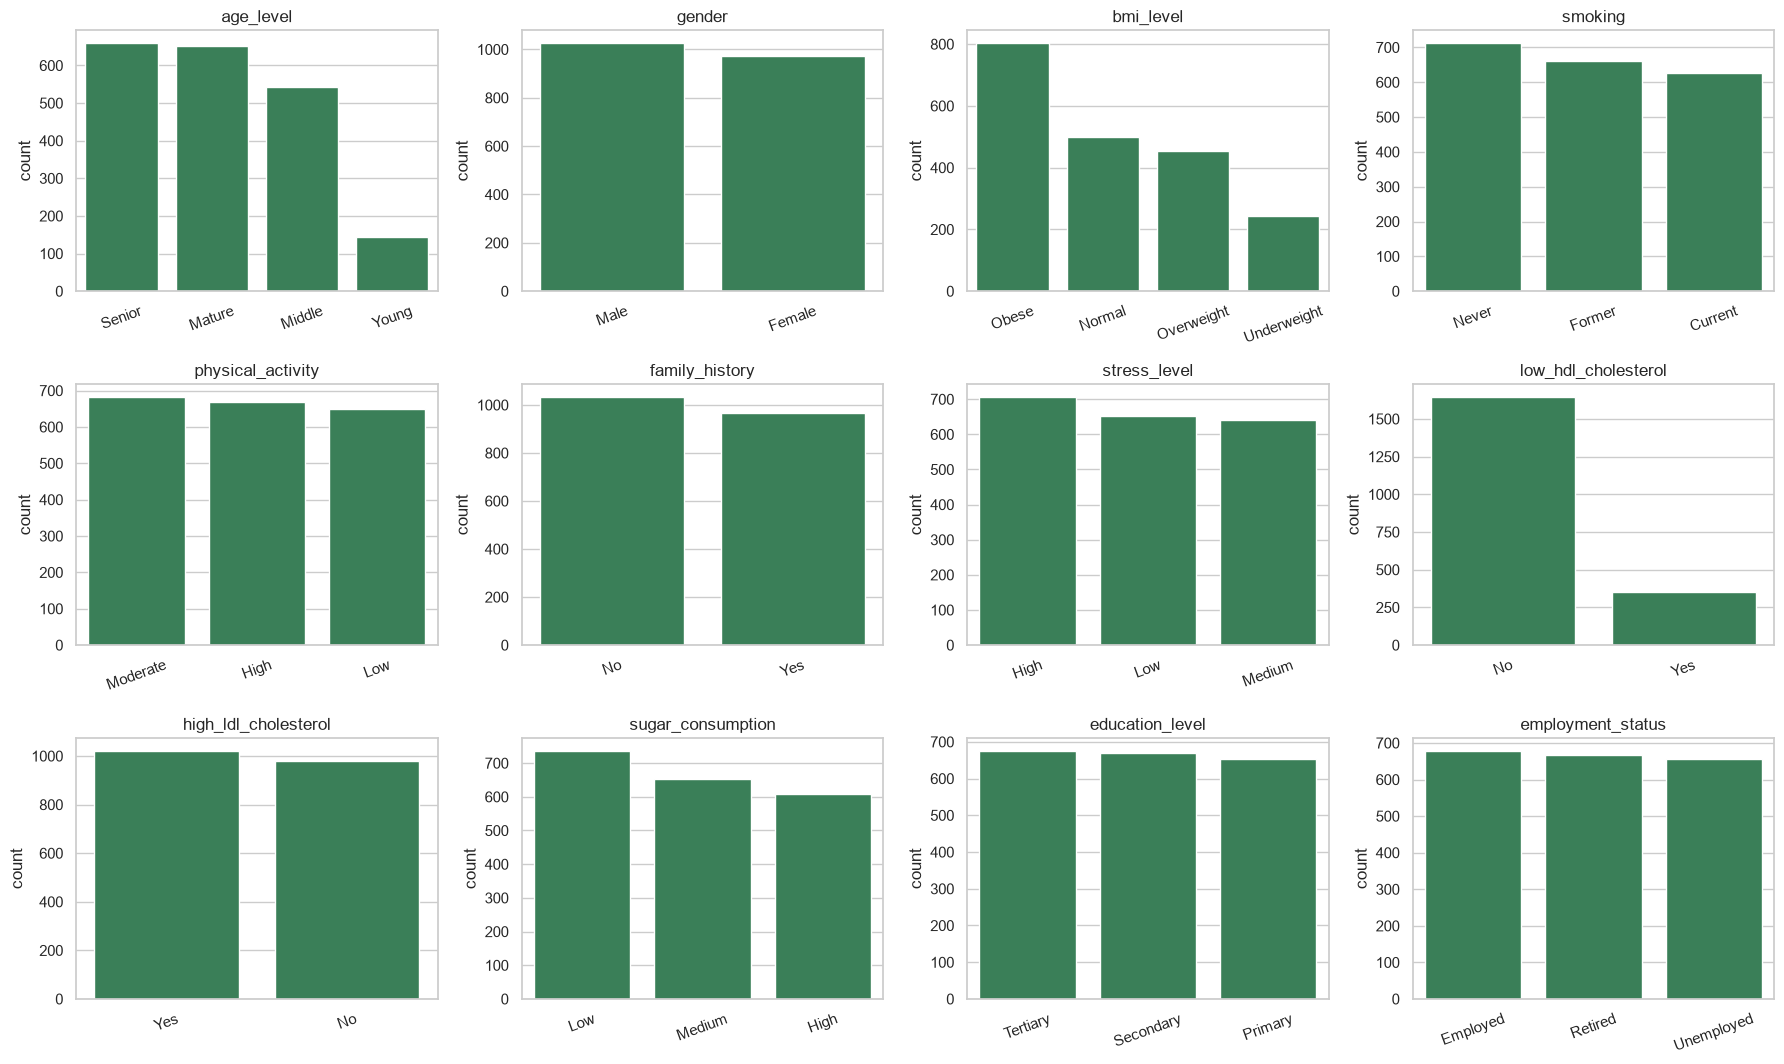

In [41]:
ncols = 4; nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.6*nrows)); axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    sns.countplot(x=df[c], ax=ax, order=df[c].value_counts().index, color='seagreen')
    ax.set_title(c); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
for ax in axes[len(cat_cols):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

- A maioria das categóricas (`gender`, `smoking`, `physical_activity`, `stress_level`, `sugar_consumption`, `family_history`, `education_level`, `employment_status`) está **equilibrada**, com proporções quase iguais por categoria.
- `bmi_level` tem mais `Obese`, `age_level` tem poucos `Young` e `low_hdl_cholesterol` é maioritariamente `No` (~82%).
- `age_level` e `bmi_level` são **derivadas** de `age` e `bmi`. As flags `low_hdl_cholesterol` e `high_ldl_cholesterol` são derivadas de `hdl` e `ldl` (verificado na secção 3.2).

## 3. Análise bivariada
### 3.1 Correlação entre features numéricas

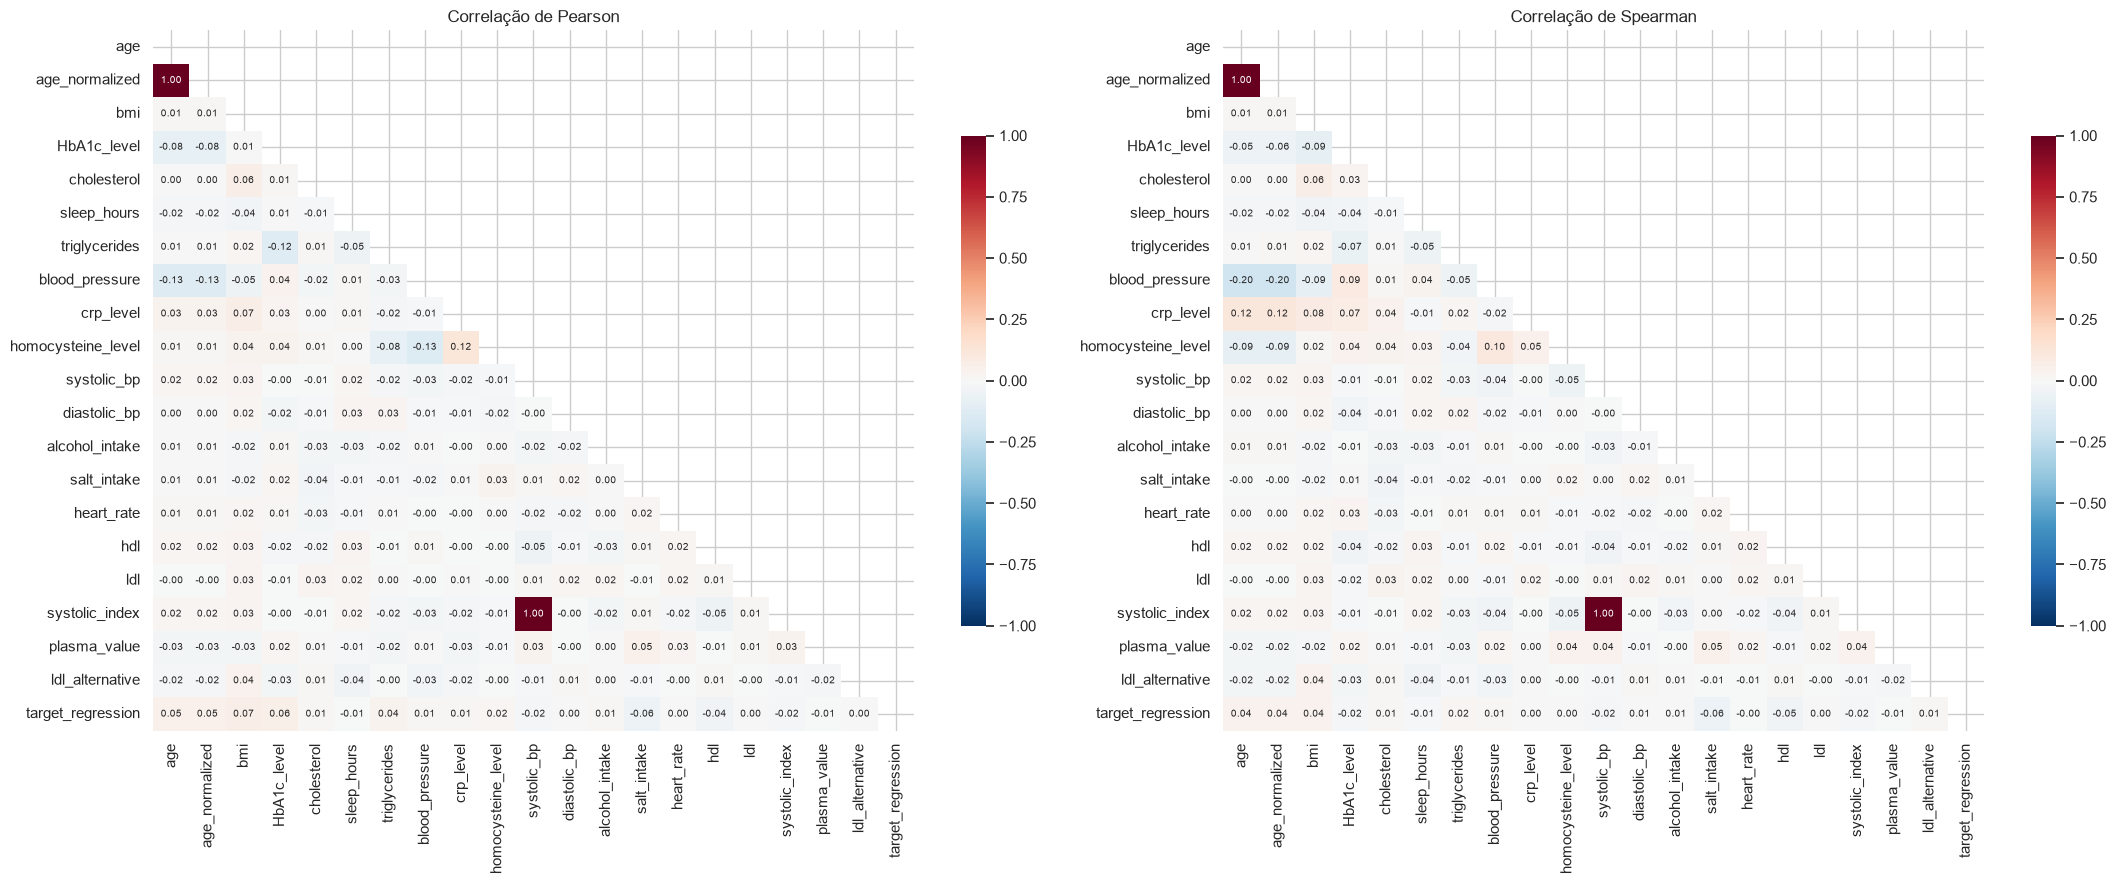

In [42]:
corr_p = df[num_cols + [TARGET_REG]].drop(columns='calcium_baseline').corr(method='pearson')
corr_s = df[num_cols + [TARGET_REG]].drop(columns='calcium_baseline').corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, m, t in zip(axes, [corr_p, corr_s], ['Pearson', 'Spearman']):
    sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), cmap='RdBu_r', vmin=-1, vmax=1,
                center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax, cbar_kws={'shrink': .7})
    ax.set_title(f'Correlação de {t}')
plt.tight_layout(); plt.show()

In [43]:
# Pares de features com |correlação| elevada
upper = corr_p.where(np.triu(np.ones(corr_p.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() > 0.3].sort_values(key=abs, ascending=False).to_frame('pearson')
high_pairs

,,pearson
systolic_bp,systolic_index,1.000
age,age_normalized,1.000


In [44]:
# age_normalized é uma transformação monótona de age? systolic_index é cópia de systolic_bp?
print('age vs age_normalized   -> Spearman:', round(stats.spearmanr(df.age, df.age_normalized)[0], 4))
print('systolic_bp == systolic_index em todas as linhas:', (df.systolic_bp == df.systolic_index).all())

# ldl_alternative tem exatamente os mesmos valores que ldl, mas noutra ordem?
print('mesmo conjunto de valores ldl / ldl_alternative:',
      np.allclose(np.sort(df.ldl), np.sort(df.ldl_alternative)))
print('corr(ldl, ldl_alternative):', round(df.ldl.corr(df.ldl_alternative), 4))

age vs age_normalized   -> Spearman: 1.0
systolic_bp == systolic_index em todas as linhas: True
mesmo conjunto de valores ldl / ldl_alternative: True
corr(ldl, ldl_alternative): -0.0049


**Conclusões sobre redundância:**
- `age` ↔ `age_normalized`: correlação ≈ 1, é apenas uma reescala. **Redundante**, basta manter uma.
- `systolic_bp` ↔ `systolic_index`: **valores idênticos** em todas as linhas. **Redundante.**
- `ldl` ↔ `ldl_alternative`: têm exatamente os mesmos valores mas **baralhados** (correlação ≈ 0). Não são redundantes no sentido linear, mas `ldl_alternative` parece ser uma **permutação de `ldl`**, ou seja, a mesma distribuição desligada do paciente. Será analisada face aos targets.
- Fora destes pares, as correlações entre features são praticamente nulas: as variáveis clínicas são quase independentes entre si, não havendo uma multicolinearidade relevante.

### 3.2 Coerência entre features derivadas e as suas variáveis de origem

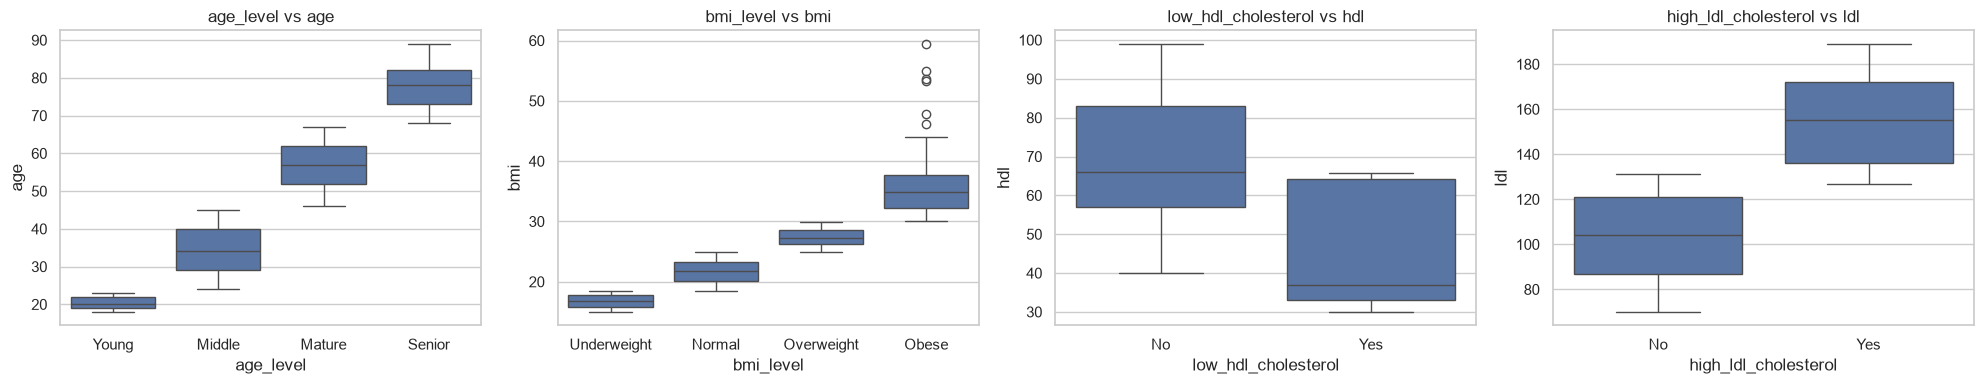

hdl < 40             False  True 
low_hdl_cholesterol              
No                    1647      0
Yes                    105    248
ldl >= 130            False  True 
high_ldl_cholesterol              
No                      940     38
Yes                     116    906


In [45]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.boxplot(data=df, x='age_level', y='age', order=['Young','Middle','Mature','Senior'], ax=axes[0])
sns.boxplot(data=df, x='bmi_level', y='bmi', order=['Underweight','Normal','Overweight','Obese'], ax=axes[1])
sns.boxplot(data=df, x='low_hdl_cholesterol', y='hdl', ax=axes[2])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl', ax=axes[3])
for ax in axes: ax.set_title(f'{ax.get_xlabel()} vs {ax.get_ylabel()}')
plt.tight_layout(); plt.show()

print(pd.crosstab(df.low_hdl_cholesterol, df.hdl < 40, colnames=['hdl < 40']))
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl >= 130, colnames=['ldl >= 130']))

As categóricas derivadas resultam de **discretizar** a variável contínua correspondente. Em `low_hdl_cholesterol` e `high_ldl_cholesterol` há alguma sobreposição (o limiar não é perfeitamente nítido), mas a associação é forte.
Estas features são **parcialmente redundantes** com a sua variável de origem. Num modelo linear, normalmente fica-se com a contínua, que contém mais informação.

### 3.3 Features numéricas vs `target_regression`

In [46]:
num_feats = [c for c in num_cols if c != 'calcium_baseline']
rel_reg = pd.DataFrame({
    'pearson': [df[c].corr(df[TARGET_REG]) for c in num_feats],
    'spearman': [df[c].corr(df[TARGET_REG], method='spearman') for c in num_feats],
    'p_value_pearson': [stats.pearsonr(df[c], df[TARGET_REG])[1] for c in num_feats],
}, index=num_feats)
rel_reg['mutual_info'] = mutual_info_regression(df[num_feats], df[TARGET_REG], random_state=RANDOM_STATE)
rel_reg = rel_reg.sort_values('pearson', key=abs, ascending=False)
rel_reg

,pearson,spearman,p_value_pearson,mutual_info
bmi,0.070,0.044,0.002,0.074
salt_intake,-0.062,-0.062,0.005,0.131
HbA1c_level,0.055,-0.023,0.013,0.084
age_normalized,0.054,0.044,0.017,0.047
age,0.054,0.043,0.017,0.049
hdl,-0.040,-0.046,0.074,0.136
triglycerides,0.037,0.019,0.096,0.108
systolic_index,-0.018,-0.016,0.426,0.133
systolic_bp,-0.018,-0.016,0.426,0.132
homocysteine_level,0.016,0.002,0.474,0.061


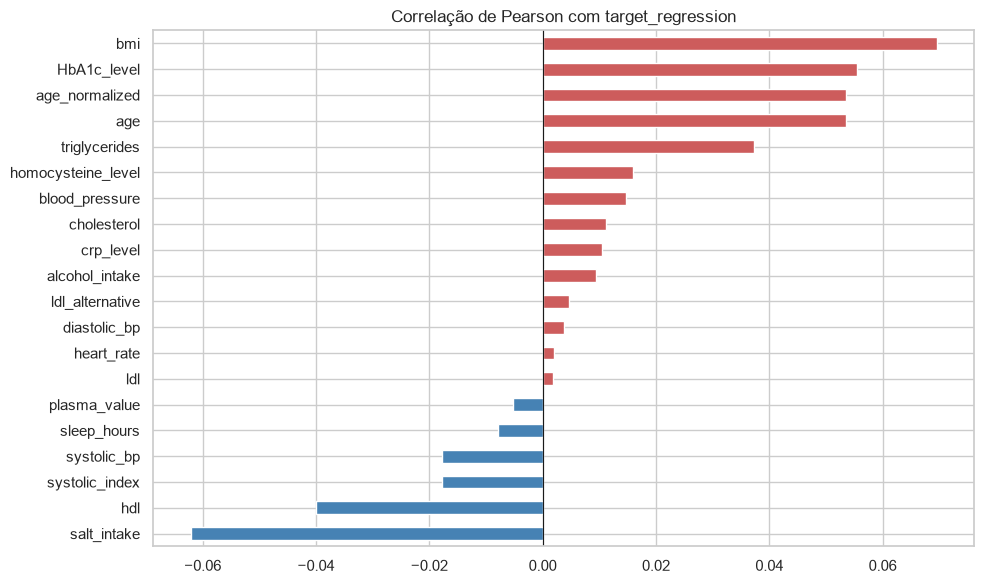

In [47]:
fig, ax = plt.subplots(figsize=(10, 6))
rel_reg['pearson'].sort_values().plot.barh(ax=ax, color=np.where(rel_reg['pearson'].sort_values() > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='k', lw=.8); ax.set_title('Correlação de Pearson com target_regression')
plt.tight_layout(); plt.show()

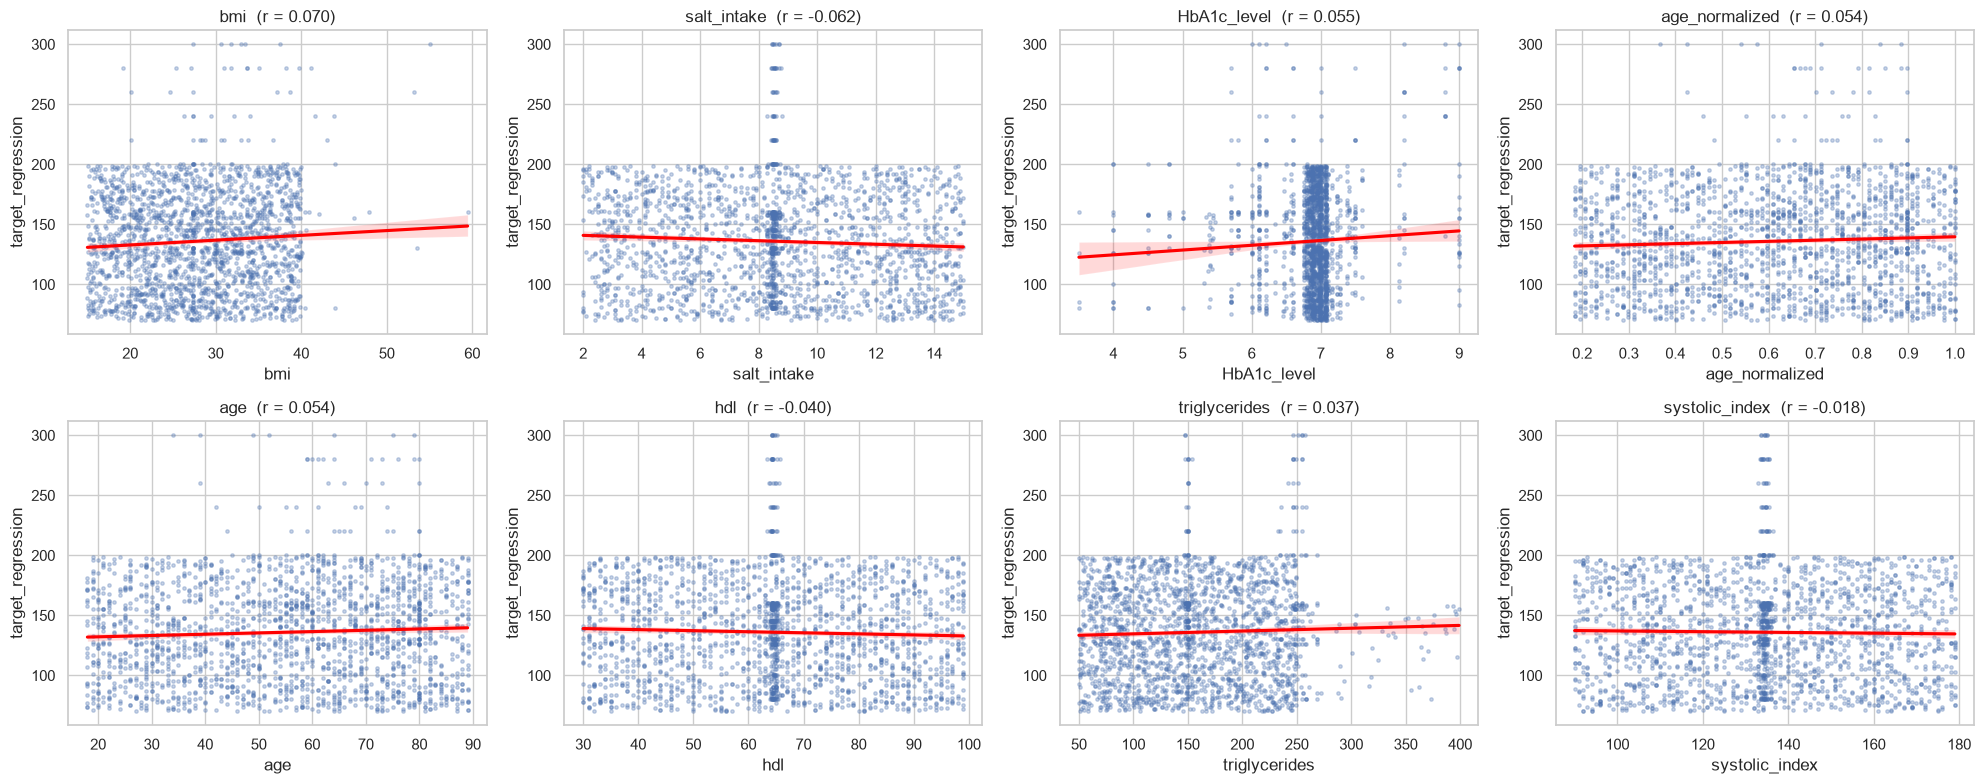

In [48]:
top = rel_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top):
    sns.regplot(data=df, x=c, y=TARGET_REG, ax=ax, scatter_kws={'s': 6, 'alpha': .3}, line_kws={'color': 'red'})
    ax.set_title(f'{c}  (r = {rel_reg.loc[c, "pearson"]:.3f})')
plt.tight_layout(); plt.show()

**Observação importante:** nenhuma feature numérica tem uma relação linear forte com `target_regression`. Os valores de |r| ficam todos abaixo de ~0.07, embora alguns (`bmi`, `salt_intake`, `HbA1c_level`, `age`) sejam estatisticamente significativos (p < 0.05) devido ao tamanho da amostra (n = 2000).
A informação mútua, que capta também relações não lineares, é igualmente baixa.

Consequência para a **regressão**: é de esperar um **R² baixo** tanto na regressão linear simples como na múltipla. A variável categórica `target_class` parece ser mais informativa (ver 3.4).

### 3.4 Features categóricas vs `target_regression`

In [49]:
rows = []
for c in cat_cols + [TARGET_CLS]:
    groups = [g[TARGET_REG].values for _, g in df.groupby(c)]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    # eta²: proporção da variância de target_regression explicada pela variável
    ss_between = sum(len(g) * (g.mean() - df[TARGET_REG].mean())**2 for g in groups)
    eta2 = ss_between / ((df[TARGET_REG] - df[TARGET_REG].mean())**2).sum()
    rows.append({'feature': c, 'F_anova': F, 'p_anova': p_anova, 'p_kruskal': p_kw, 'eta2': eta2})
cat_reg = pd.DataFrame(rows).set_index('feature').sort_values('eta2', ascending=False)
cat_reg

,F_anova,p_anova,p_kruskal,eta2
feature,,,,
target_class,27.881,0.000,0.000,0.027
smoking,6.043,0.002,0.004,0.006
age_level,3.593,0.013,0.039,0.005
bmi_level,2.245,0.081,0.330,0.003
physical_activity,3.068,0.047,0.333,0.003
sugar_consumption,0.926,0.396,0.485,0.001
family_history,1.842,0.175,0.187,0.001
high_ldl_cholesterol,1.541,0.215,0.356,0.001
education_level,0.700,0.496,0.431,0.001


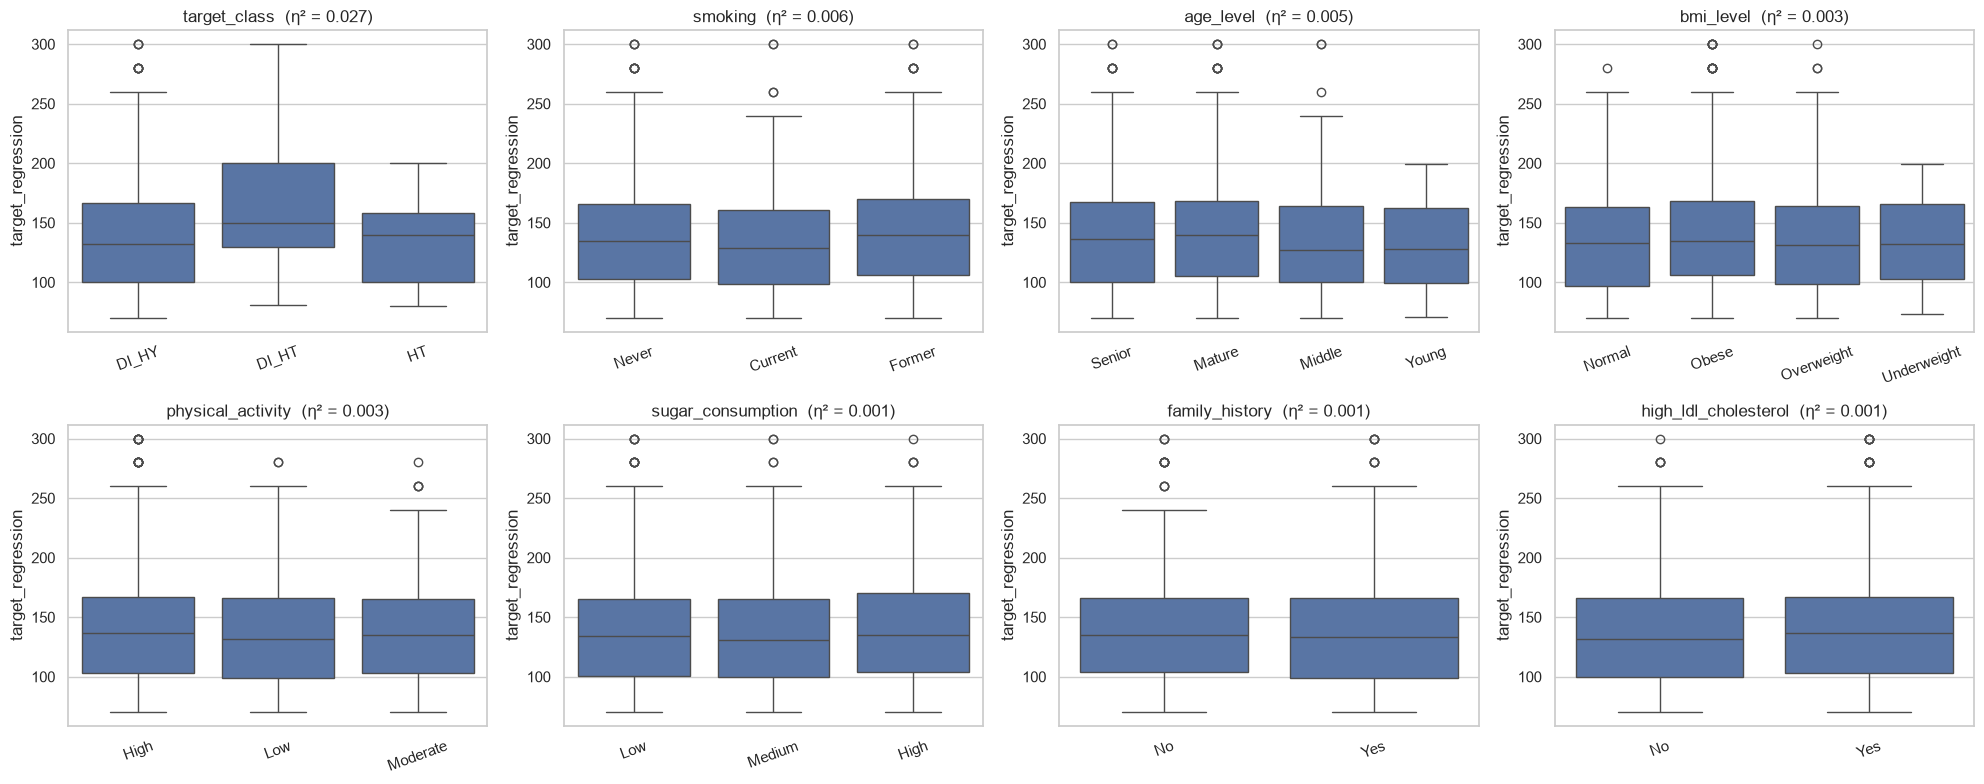

In [50]:
plot_cats = cat_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, plot_cats):
    sns.boxplot(data=df, x=c, y=TARGET_REG, ax=ax)
    ax.set_title(f'{c}  (η² = {cat_reg.loc[c, "eta2"]:.3f})'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

- `target_class` é a variável com mais efeito sobre `target_regression`: a classe `DI_HT` tem uma média claramente mais alta (~168, contra ~134 nas outras).
- As restantes categóricas têm um efeito quase nulo (η² ≈ 0). Os testes ANOVA/Kruskal-Wallis permitem ver quais têm alguma diferença estatisticamente significativa.

### 3.5 Features numéricas vs `target_class`

In [51]:
classes = df[TARGET_CLS].value_counts().index.tolist()
rows = []
for c in num_feats:
    groups = [df.loc[df[TARGET_CLS] == k, c] for k in classes]
    H, p = stats.kruskal(*groups)
    ss_b = sum(len(g) * (g.mean() - df[c].mean())**2 for g in groups)
    eta2 = ss_b / ((df[c] - df[c].mean())**2).sum()
    rows.append({'feature': c, **{f'mean_{k}': g.mean() for k, g in zip(classes, groups)},
                 'kruskal_H': H, 'p_value': p, 'eta2': eta2})
num_cls = pd.DataFrame(rows).set_index('feature')
num_cls['mutual_info'] = mutual_info_classif(df[num_feats], df[TARGET_CLS], random_state=RANDOM_STATE)
num_cls = num_cls.sort_values('mutual_info', ascending=False)
num_cls

,mean_DI_HY,mean_HT,mean_DI_HT,kruskal_H,p_value,eta2,mutual_info
feature,,,,,,,
hdl,64.478,64.502,64.545,0.110,0.946,0.000,0.294
systolic_bp,134.268,134.493,134.524,0.092,0.955,0.000,0.291
alcohol_intake,14.945,15.009,14.953,0.519,0.771,0.000,0.289
ldl,129.897,129.383,129.533,0.056,0.972,0.000,0.286
systolic_index,134.268,134.493,134.524,0.092,0.955,0.000,0.285
diastolic_bp,89.452,89.511,89.529,0.012,0.994,0.000,0.284
heart_rate,74.419,74.341,74.468,0.021,0.990,0.000,0.282
salt_intake,8.583,8.495,8.532,0.312,0.856,0.000,0.278
triglycerides,151.159,217.040,227.074,170.839,0.000,0.105,0.242


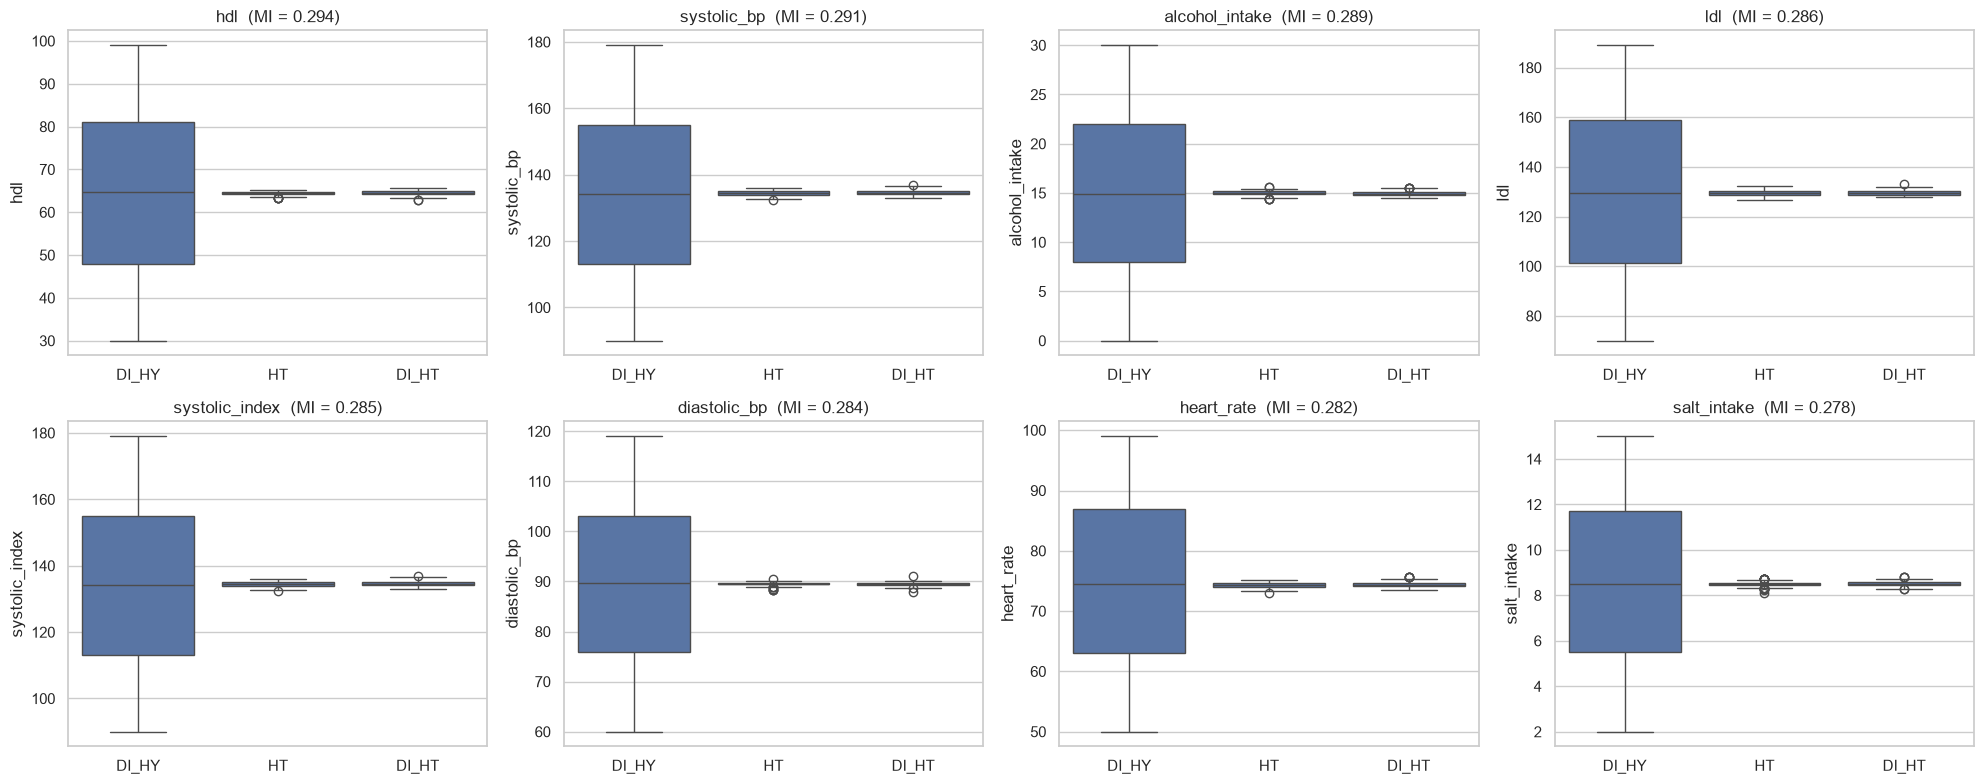

In [52]:
top_cls = num_cls.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top_cls):
    sns.boxplot(data=df, x=TARGET_CLS, y=c, order=classes, ax=ax)
    ax.set_title(f'{c}  (MI = {num_cls.loc[c, "mutual_info"]:.3f})'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

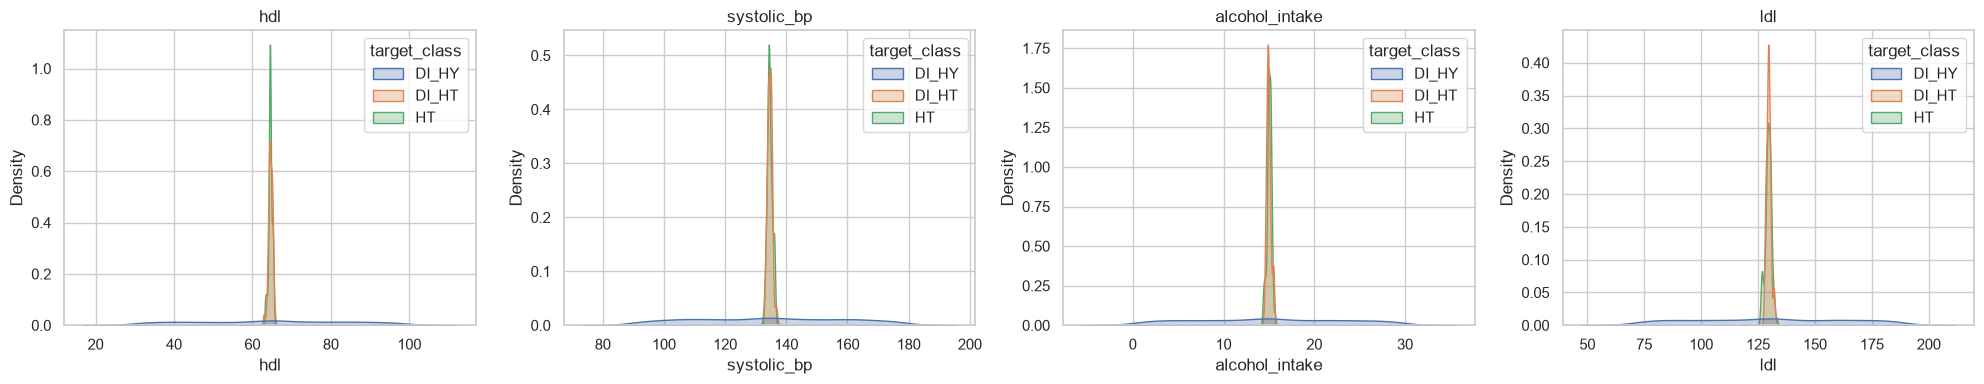

In [53]:
# Densidades por classe (normalizadas por classe, para compensar o desequilíbrio)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, num_cls.index[:4]):
    sns.kdeplot(data=df, x=c, hue=TARGET_CLS, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Features mais discriminativas para a classificação:**
- **`HbA1c_level`**: a classe `HT` tem uma HbA1c média muito mais baixa (~5.4%, contra ~6.9–7.0% nas classes com diabetes, `DI_*`). Isto faz sentido clinicamente, porque HbA1c é o marcador de diabetes e `HT` é a única classe sem componente diabética. É a feature que melhor separa `HT` das outras.
- **`triglycerides`**: valores mais altos em `DI_HT` e `HT` (~220) do que em `DI_HY` (~150).
- **`age`/`age_normalized`** e **`bmi`**: médias um pouco mais altas nas classes minoritárias.
- **`ldl_alternative`**, `crp_level` e `blood_pressure` mostram diferenças pequenas mas por vezes significativas.
- Features como `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake` e `salt_intake` têm médias e distribuições praticamente iguais entre classes (Kruskal-Wallis com p elevado, η² ≈ 0): pelo seu **valor clínico**, são **pouco informativas**.

⚠️ **Atenção:** a informação mútua (MI) dá precisamente a estas features os valores **mais altos**, o que contradiz os testes anteriores. A secção 3.8 explica porquê: trata-se de um **artefacto dos dados**, não de um sinal clínico.

### 3.6 Features categóricas vs `target_class` (χ² e V de Cramér)

In [54]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), chi2, p

rows = []
for c in cat_cols:
    v, chi2, p = cramers_v(df[c], df[TARGET_CLS])
    rows.append({'feature': c, 'chi2': chi2, 'p_value': p, 'cramers_v': v})
cat_cls = pd.DataFrame(rows).set_index('feature').sort_values('cramers_v', ascending=False)
cat_cls

,chi2,p_value,cramers_v
feature,,,
low_hdl_cholesterol,31.042,0.000,0.125
age_level,50.711,0.000,0.113
bmi_level,46.506,0.000,0.108
physical_activity,19.793,0.001,0.070
education_level,15.257,0.004,0.062
sugar_consumption,13.796,0.008,0.059
employment_status,13.748,0.008,0.059
smoking,13.380,0.010,0.058
family_history,6.147,0.046,0.055


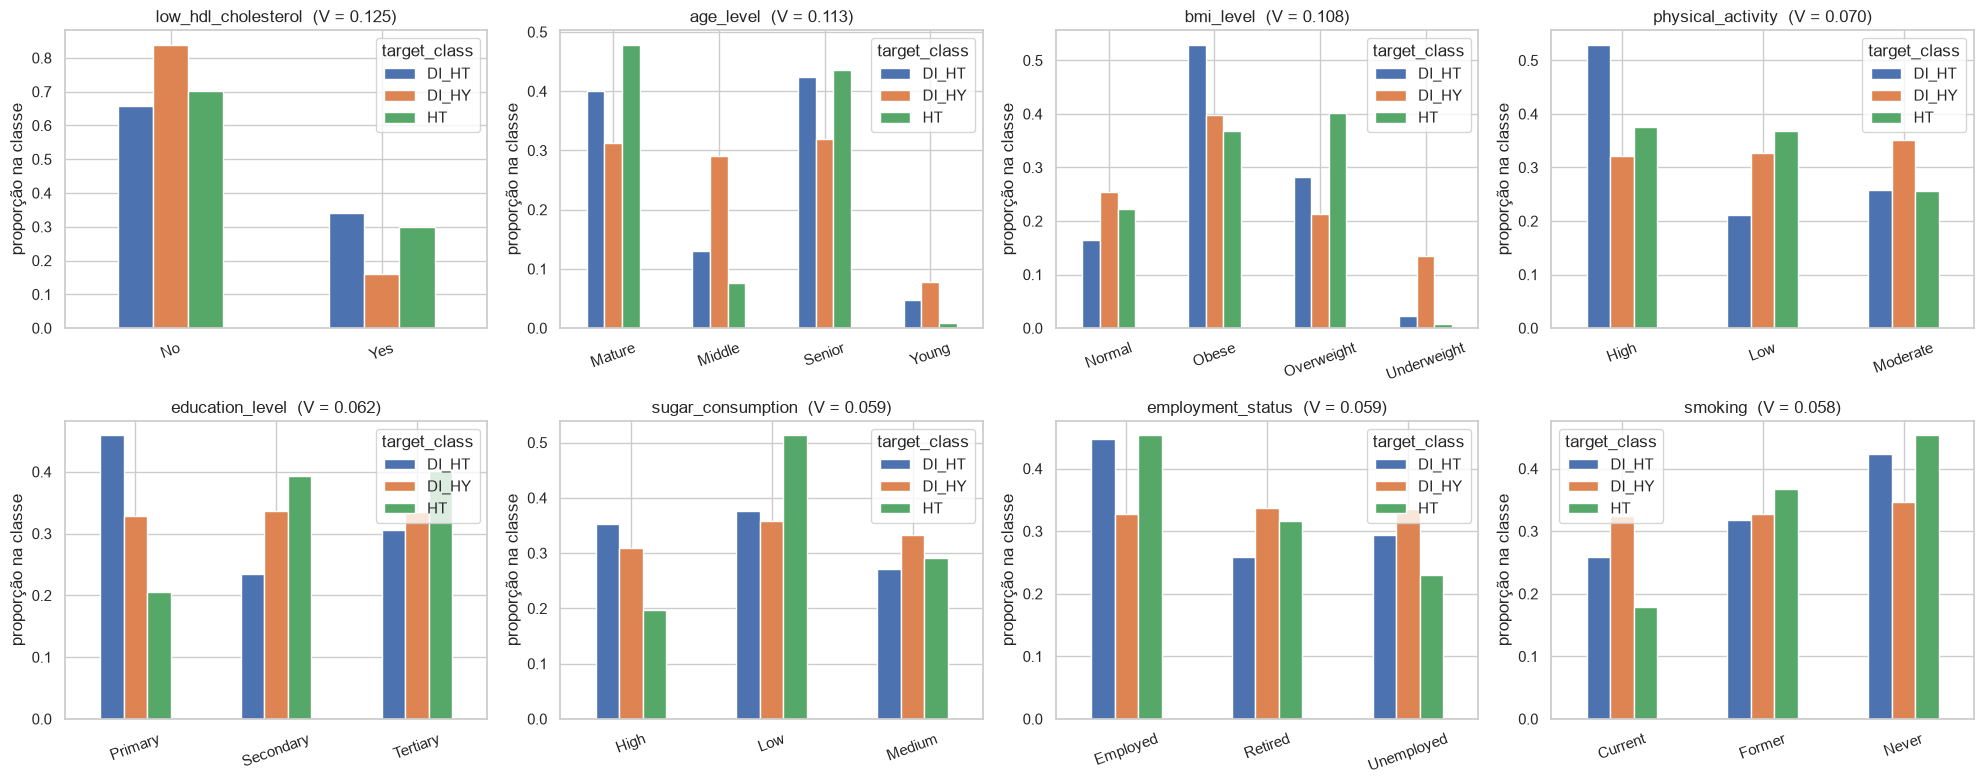

In [55]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cls.index[:8]):
    ct = pd.crosstab(df[c], df[TARGET_CLS], normalize='columns')   # % de cada classe por categoria
    ct.plot.bar(ax=ax, rot=20)
    ax.set_title(f'{c}  (V = {cat_cls.loc[c, "cramers_v"]:.3f})'); ax.set_xlabel(''); ax.set_ylabel('proporção na classe')
plt.tight_layout(); plt.show()

- As associações mais fortes são as de `low_hdl_cholesterol`, `age_level` e `bmi_level`, embora todas **fracas** (V ≈ 0.11–0.13). `age_level`/`bmi_level` confirmam o efeito de `age` e `bmi` visto em 3.5; por exemplo, quase não há doentes `Underweight` nas classes `HT`/`DI_HT`.
- É curioso que `low_hdl_cholesterol` esteja associada à classe quando `hdl` não está (médias iguais em 3.5). Isto bate com a sobreposição imperfeita do limiar visto em 3.2 e é provavelmente outra consequência do artefacto descrito em 3.8.
- Variáveis como `physical_activity`, `education_level`, `smoking` e `employment_status` têm p < 0.05 mas V ≈ 0.06. Com n = 2000, efeitos muito pequenos tornam-se "significativos", por isso a sua **relevância prática é reduzida**. `gender` e `stress_level` não têm associação (p > 0.2).

### 3.7 Relação entre os dois targets e pairplot das features mais relevantes

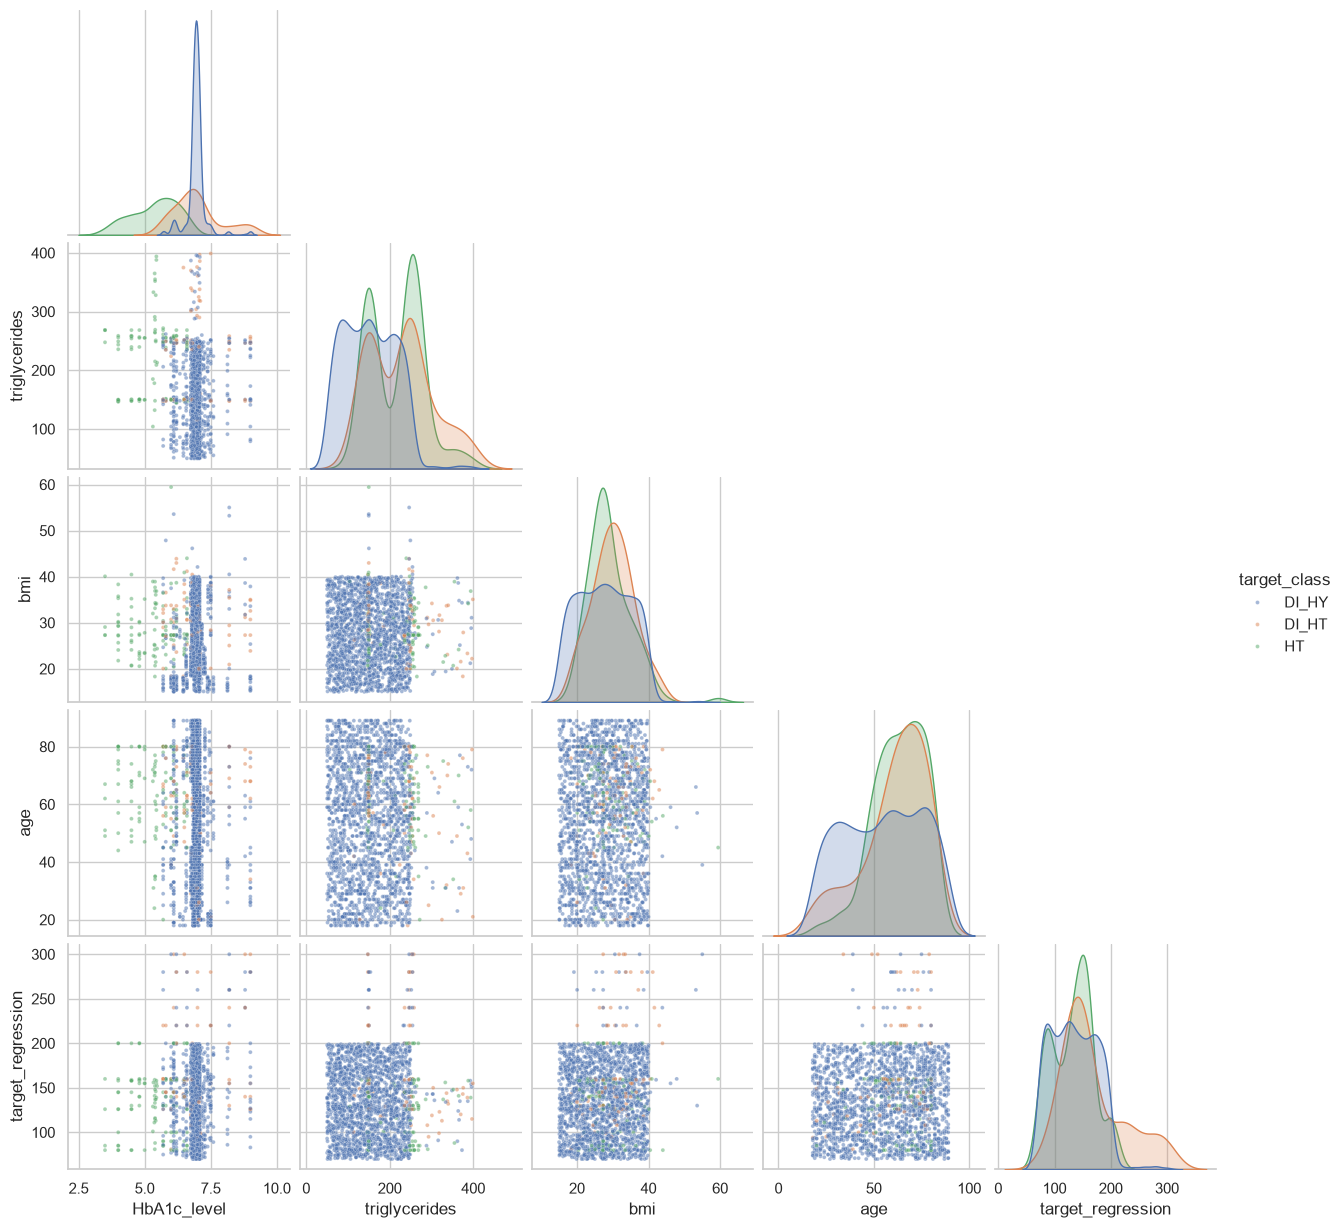

In [56]:
key = ['HbA1c_level', 'triglycerides', 'bmi', 'age', TARGET_REG]
sns.pairplot(df[key + [TARGET_CLS]], hue=TARGET_CLS, corner=True, plot_kws={'s': 8, 'alpha': .5},
             diag_kws={'common_norm': False})
plt.show()

O pairplot mostra que `HbA1c_level` isola bem a classe `HT`, e que a combinação com `triglycerides` ajuda a separar `DI_HT`/`HT` de `DI_HY`. Ainda assim, há bastante sobreposição entre `DI_HT` e `DI_HY`, que deverá ser a distinção mais difícil para os classificadores.

### 3.8 Artefacto detetado: precisão decimal dos valores depende da classe
Olhando para as linhas do dataset, alguns valores são números "redondos" (`hdl = 72.0`) e outros têm muitas casas decimais (`hdl = 64.3313679245283`), o que sugere que foram imputados ou gerados sinteticamente. Vamos verificar se isto está relacionado com a classe.

In [57]:
# Proporção de valores com mais de 1 casa decimal (não arredondados), por classe
def not_rounded(s):
    return ((s * 10).round(6) % 1 != 0)

frac = pd.DataFrame({c: df.groupby(TARGET_CLS)[c].apply(lambda s: not_rounded(s).mean())
                     for c in num_feats}).T[classes]
frac.sort_values('DI_HY')

target_class,DI_HY,HT,DI_HT
age,0.000,0.000,0.000
cholesterol,0.031,0.812,0.671
triglycerides,0.031,0.812,0.671
bmi,0.049,0.923,0.953
systolic_index,0.053,1.000,0.941
systolic_bp,0.053,1.000,0.941
ldl,0.056,1.000,1.000
sleep_hours,0.056,1.000,1.000
hdl,0.056,1.000,1.000
heart_rate,0.056,1.000,1.000


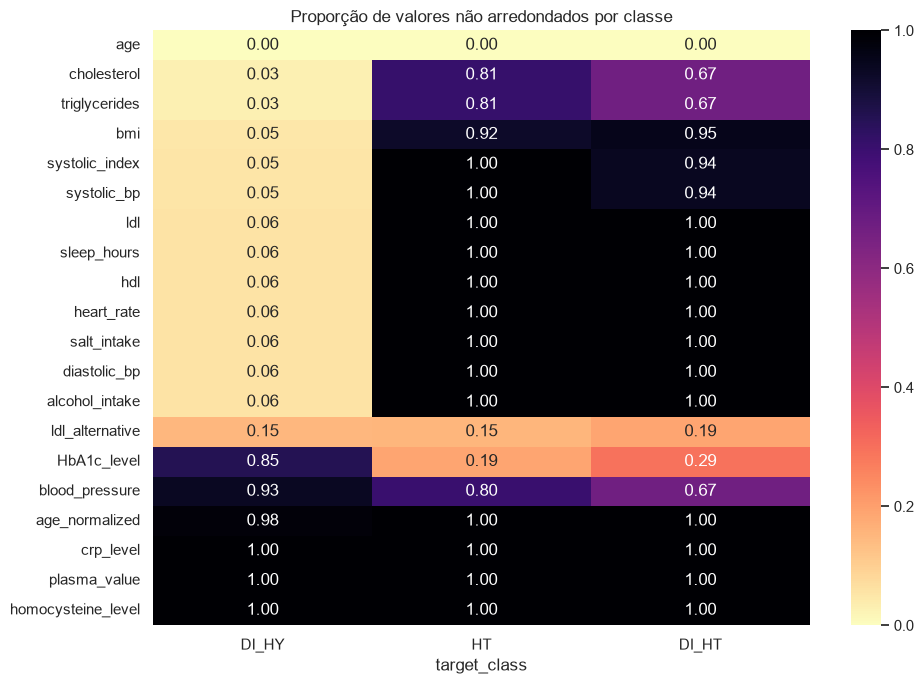

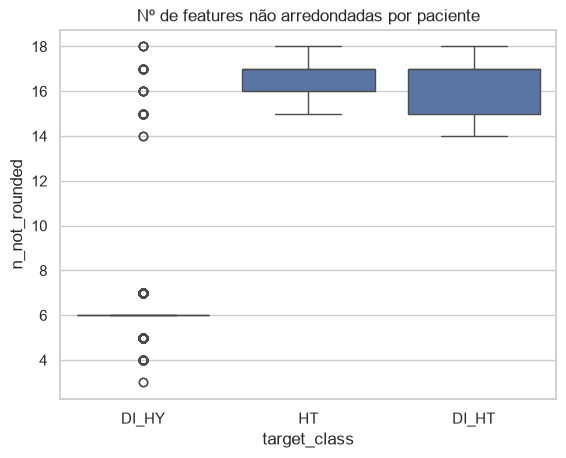

In [58]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(frac.sort_values('DI_HY'), annot=True, fmt='.2f', cmap='magma_r', ax=ax)
ax.set_title('Proporção de valores não arredondados por classe')
plt.tight_layout(); plt.show()

# Quanto vale este "sinal"? Nº de features não arredondadas por paciente vs classe
df_tmp = df.assign(n_not_rounded=sum(not_rounded(df[c]).astype(int) for c in num_feats))
sns.boxplot(data=df_tmp, x=TARGET_CLS, y='n_not_rounded', order=classes)
plt.title('Nº de features não arredondadas por paciente'); plt.show()

**Conclusão:** nas classes minoritárias (`HT`, `DI_HT`), praticamente todos os valores de `hdl`, `heart_rate`, `alcohol_intake`, `systolic_bp`, `bmi`, ... têm muitas casas decimais. Na classe `DI_HY`, só ~5% dos valores estão nessa situação (com `HbA1c_level` acontece o inverso).
Isto indica que os registos das classes minoritárias foram **gerados ou imputados por um processo diferente** (por exemplo, *oversampling* sintético ou imputação pela média), e explica a MI alta em features cujas distribuições, de resto, são iguais entre classes.

**Implicações:**
- Um modelo flexível pode aprender a classe a partir da **"forma" do número** e não do seu valor clínico. Isto é *data leakage* e leva a um desempenho otimista que não generalizaria para dados reais.
- Os modelos lineares pedidos (Regressão Logística e LDA) usam o valor e não a precisão decimal, por isso são pouco afetados. Mesmo assim, **não devemos criar features derivadas da precisão**, e a MI deve ser interpretada com cautela neste dataset.
- Para avaliar relevância clínica usamos sobretudo os testes de Kruskal-Wallis/η², χ²/V de Cramér e as correlações.

## 4. Síntese: features constantes, redundantes e pouco informativas

In [59]:
summary = pd.DataFrame(index=num_feats + cat_cols)
summary['|r| target_reg'] = rel_reg['pearson'].abs()
summary['eta2 target_reg (cat)'] = cat_reg['eta2']
summary['MI target_class'] = num_cls['mutual_info']
summary['CramersV target_class'] = cat_cls['cramers_v']
summary['p target_class'] = num_cls['p_value'].combine_first(cat_cls['p_value'])
summary.sort_values('p target_class')

,|r| target_reg,eta2 target_reg (cat),MI target_class,CramersV target_class,p target_class
HbA1c_level,0.055,NaN,0.208,NaN,0.000
triglycerides,0.037,NaN,0.242,NaN,0.000
blood_pressure,0.015,NaN,0.196,NaN,0.000
age_level,NaN,0.005,NaN,0.113,0.000
bmi_level,NaN,0.003,NaN,0.108,0.000
low_hdl_cholesterol,NaN,0.001,NaN,0.125,0.000
age_normalized,0.054,NaN,0.133,NaN,0.000
age,0.054,NaN,0.034,NaN,0.000
homocysteine_level,0.016,NaN,0.179,NaN,0.000
physical_activity,NaN,0.003,NaN,0.070,0.001


| Tipo | Feature(s) | Justificação | Ação proposta |
|---|---|---|---|
| **Constante** | `calcium_baseline` | Valor único (9.42), desvio padrão 0 | Remover |
| **Redundante** | `systolic_index` | Idêntica a `systolic_bp` em todas as linhas | Remover (manter `systolic_bp`) |
| **Redundante** | `age_normalized` | Reescala de `age` (Spearman = 1) | Remover (manter `age`) |
| **Parcialmente redundante** | `age_level`, `bmi_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | Discretizações de `age`, `bmi`, `hdl`, `ldl` | Preferir a variável contínua; testar na seleção de features |
| **Suspeita** | `ldl_alternative` | Mesmos valores de `ldl` mas permutados (r ≈ 0 com `ldl`) | Tratar com cautela; avaliar com Lasso |
| **Pouco informativas** | `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake`, `salt_intake`, `sleep_hours`, `cholesterol`, `plasma_value` e categóricas sociodemográficas/comportamentais | Distribuições iguais entre classes (Kruskal p elevado, η²/V ≈ 0; a MI alta deve-se ao artefacto da secção 3.8) e correlação ≈ 0 com `target_regression` | Candidatas a eliminação; confirmar com Ridge/Lasso (secção 5) |
| **Informativas** | `HbA1c_level`, `triglycerides`, `bmi`/`bmi_level`, `age`/`age_level` | Diferenças claras entre classes | Manter |

**Conclusões gerais da EDA**
1. Os dados estão limpos: sem valores em falta nem duplicados. Há *outliers* em algumas variáveis clínicas, mas parecem informativos e não serão removidos às cegas.
2. `target_class` está **muito desequilibrada** (~90% `DI_HY`). Isto obriga a usar estratificação e métricas robustas (F1 macro, *balanced accuracy*, recall por classe).
3. `target_regression` tem uma relação **muito fraca** com as features numéricas, por isso é de esperar R² baixo nos modelos lineares. A variável mais associada é `target_class` (média mais alta em `DI_HT`).
4. Para a classificação, os preditores mais relevantes são **`HbA1c_level`** (separa `HT`) e **`triglycerides`**, seguidos de `bmi` e `age`.
5. **Artefacto:** a precisão decimal dos valores depende da classe (registos das classes minoritárias provavelmente sintéticos ou imputados), o que é uma potencial fonte de *leakage*.
6. Há 1 feature constante e 2 redundantes que devem ser removidas, e um conjunto alargado de features pouco informativas a validar mais à frente com regularização (Lasso).